# Lab 2: Text Pre-processing and Regular Expressions – Tasks

This notebook contains the solutions of the four tasks of **Lab 2**, each with its output:

| Task | Topic |
| --- | --- |
| 1 | Hashtag analysis of the Apple tweets dataset (regex + pre-processing) |
| 2 | Using `re.compile()` |
| 3 | Using `re.split()` |
| 4 | Tokenization with spaCy (and comparison with NLTK) |

**Dataset for Task 1:** `apple-twitter-sentiment-texts.csv` from Kaggle
(<https://www.kaggle.com/datasets/seriousran/appletwittersentimenttexts>). It is stored in the same folder as this notebook (`Lab2/`).

## Setup

In [1]:
import re
import sys
import subprocess
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import nltk
import spacy

# NLTK tokenizer models (needed in Task 4)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# spaCy small English model (needed in Task 4) - download it only if it is missing
if not spacy.util.is_package('en_core_web_sm'):
    subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm'], check=True)

print('Setup finished')

Setup finished


---
# Task 1: Hashtags in the Apple tweets dataset

**Goal:** find **how many hashtags** are used in the dataset and the **top 10 hashtags**.

**Plan**
1. Load the dataset.
2. Extract the hashtags from every tweet with a regular expression.
3. Count them (total, unique) and get the top 10 on the *raw* text.
4. Apply a pre-processing step (lower casing) and count again, to see why pre-processing matters.

### Step 1: Load the dataset

In [2]:
df = pd.read_csv('apple-twitter-sentiment-texts.csv', encoding='utf-8-sig')

print('Shape:', df.shape)
print('Columns:', list(df.columns))
df.head()

Shape: (1630, 2)
Columns: ['text', 'sentiment']


,text,sentiment
0,Wow. Yall needa step it up @Apple RT @heynyla:...,-1
1,What Happened To Apple Inc? http://t.co/FJEX...,0
2,Thank u @apple I can now compile all of the pi...,1
3,The oddly uplifting story of the Apple co-foun...,0
4,@apple can i exchange my iphone for a differen...,0


### Step 2: Extract the hashtags with a regular expression

A hashtag is a `#` followed by one or more word characters, so the pattern is `#\w+`:

- `#` matches the hash sign itself.
- `\w+` matches one or more letters, digits or underscores (`[a-zA-Z0-9_]`).

`re.findall()` returns **all** matches in a tweet as a list (a tweet may contain several hashtags or none).

In [3]:
# list of hashtags for every tweet
hashtags_per_tweet = df['text'].apply(lambda tweet: re.findall(r'#\w+', tweet))

# flatten into one list holding every hashtag occurrence
all_hashtags = [tag for tags in hashtags_per_tweet for tag in tags]

print('Number of tweets                        :', len(df))
print('Tweets with at least one hashtag        :', (hashtags_per_tweet.str.len() > 0).sum())
print('TOTAL number of hashtags (with repeats) :', len(all_hashtags))
print('Unique hashtags (case-sensitive)        :', len(set(all_hashtags)))
print()
print('First 5 tweets that contain hashtags:')
shown = 0
for tweet, tags in zip(df['text'], hashtags_per_tweet):
    if tags:
        print(' ', tags, '<-', ' '.join(tweet.split())[:80])
        shown += 1
        if shown == 5:
            break

Number of tweets                        : 1630
Tweets with at least one hashtag        : 783
TOTAL number of hashtags (with repeats) : 1616
Unique hashtags (case-sensitive)        : 607

First 5 tweets that contain hashtags:
  ['#Note4'] <- Wow. Yall needa step it up @Apple RT @heynyla: Music and snapchat at the same da
  ['#aapl', '#apple'] <- What Happened To Apple Inc? http://t.co/FJEXI3oP0U #aapl #apple @MoneyPress http
  ['#aapl'] <- The oddly uplifting story of the Apple co-founder who sold his stake for $800 $A
  ['#aapl'] <- RT @JPDesloges: Apple Acted Unfairly In Suppressing Digital Music Competition: P
  ['#AAPL'] <- Apple Inc. Deleted Songs From Rival Services From iPods http://t.co/dQwDFpcc4x #


### Step 3: Top 10 hashtags on the **raw** text (no pre-processing)

In [4]:
raw_counts = Counter(all_hashtags)

top10_raw = pd.DataFrame(raw_counts.most_common(10), columns=['hashtag', 'count'])
top10_raw.index = range(1, 11)
top10_raw

,hashtag,count
1,#AAPL,203
2,#aapl,197
3,#Apple,134
4,#December,37
5,#iPhone,33
6,#apple,27
7,#iPhone6,24
8,#Monday,9
9,#SteveJobs,9
10,#trading,9


**Observation:** the same hashtag is counted several times under different spellings, e.g. `#AAPL` and `#aapl`, or `#Apple` and `#apple`.
For a computer these are different strings, so the counts are split and the ranking is misleading. This is exactly why we need **text pre-processing**.

### Step 4: Pre-processing: lower casing, then count again

Converting every hashtag to lower case merges the different spellings into one.

In [5]:
clean_hashtags = [tag.lower() for tag in all_hashtags]
clean_counts = Counter(clean_hashtags)

print('TOTAL number of hashtags (with repeats) :', len(clean_hashtags))
print('Unique hashtags BEFORE lower casing     :', len(raw_counts))
print('Unique hashtags AFTER  lower casing     :', len(clean_counts))
print()

top10 = pd.DataFrame(clean_counts.most_common(10), columns=['hashtag', 'count'])
top10.index = range(1, 11)
top10

TOTAL number of hashtags (with repeats) : 1616
Unique hashtags BEFORE lower casing     : 607
Unique hashtags AFTER  lower casing     : 555



,hashtag,count
1,#aapl,400
2,#apple,162
3,#iphone,38
4,#december,37
5,#iphone6,29
6,#stocks,15
7,#ipad,14
8,#iphone6plus,13
9,#iphone6s,13
10,#tech,12


In [6]:
# Compare the ranking before and after pre-processing
comparison = pd.concat(
    [top10_raw.add_suffix(' (raw)'), top10.add_suffix(' (lower-cased)')],
    axis=1
)
comparison

,hashtag (raw),count (raw),hashtag (lower-cased),count (lower-cased)
1,#AAPL,203,#aapl,400
2,#aapl,197,#apple,162
3,#Apple,134,#iphone,38
4,#December,37,#december,37
5,#iPhone,33,#iphone6,29
6,#apple,27,#stocks,15
7,#iPhone6,24,#ipad,14
8,#Monday,9,#iphone6plus,13
9,#SteveJobs,9,#iphone6s,13
10,#trading,9,#tech,12


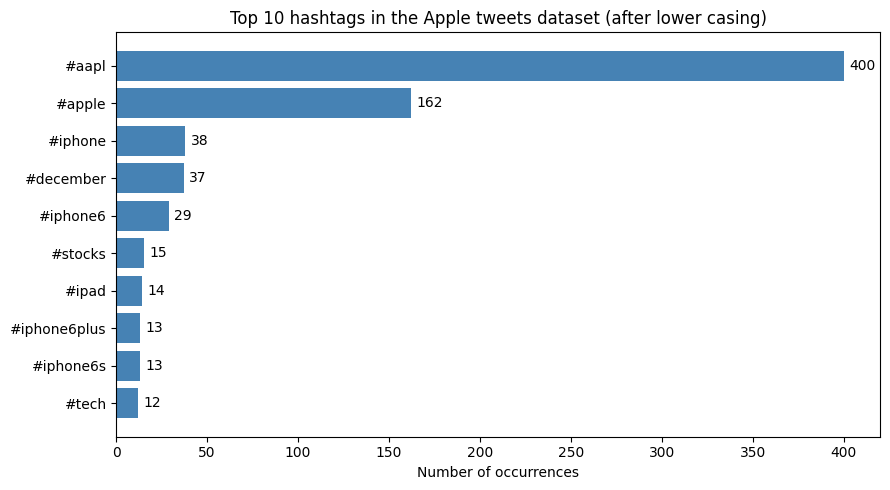

In [7]:
# Bar chart of the final top 10
plt.figure(figsize=(9, 5))
plt.barh(top10['hashtag'][::-1], top10['count'][::-1], color='steelblue')
plt.xlabel('Number of occurrences')
plt.title('Top 10 hashtags in the Apple tweets dataset (after lower casing)')
for y, c in enumerate(top10['count'][::-1]):
    plt.text(c + 3, y, str(c), va='center')
plt.tight_layout()
plt.show()

### Task 1 – Result

**How many hashtags are used?**
- **1,616 hashtags** in total (counting repeats), appearing in **783 of the 1,630 tweets**.
- **607** different hashtags if upper/lower case is treated as different, but only **555** unique hashtags after lower casing.

**Top 10 hashtags (after lower casing):**

| Rank | Hashtag | Count |
| --- | --- | --- |
| 1 | `#aapl` | 400 |
| 2 | `#apple` | 162 |
| 3 | `#iphone` | 38 |
| 4 | `#december` | 37 |
| 5 | `#iphone6` | 29 |
| 6 | `#stocks` | 15 |
| 7 | `#ipad` | 14 |
| 8 | `#iphone6plus` | 13 |
| 9 | `#iphone6s` | 13 |
| 10 | `#tech` | 12 |

**Why pre-processing matters:** on the raw text `#AAPL` (203) and `#aapl` (197) look like two different hashtags, and `#Apple` (134), `#apple` (27) and `#APPLE` (1) look like three. After lower casing they merge into `#aapl` (400) and `#apple` (162).
The ranking itself also changes: `#Monday`, `#SteveJobs` and `#trading` were in the raw top 10, but they drop out once the split counts of `#iPhone6`, `#iPad`, `#stocks` and `#tech` are merged.

**Side note:** the pattern `#\w+` also matches purely numeric tags such as `#2015` or `#1` (which Twitter itself does not treat as hashtags). The check below shows how little this changes the result.

In [8]:
numeric_only = [tag for tag in all_hashtags if re.fullmatch(r'#\d+', tag)]
print('Purely numeric "hashtags":', len(numeric_only), numeric_only)
print('Total hashtags if they are excluded:', len(all_hashtags) - len(numeric_only))

Purely numeric "hashtags": 11 ['#1', '#2015', '#2015', '#6', '#2015', '#4', '#1', '#2014', '#6', '#6', '#2015']
Total hashtags if they are excluded: 1605


---
# Task 2: Using `re.compile()`

Given the text `"This year is 2021"`:
1. Compile a pattern that matches one or more digits.
2. Print the type of the compiled pattern.
3. Use the compiled pattern to replace `2021` with `2022`.
4. Print the updated text.
5. Explain what `re.compile()` does and why it is useful.

In [ ]:
text = "This year is 2021"

# 1 
pattern = re.compile(r'\d+')

# 2
print(type(pattern))

# 3
new_text = pattern.sub('2022', text)

# 4
print(new_text)

<class 're.Pattern'>
This year is 2022


**5. Explanation – what is `re.compile()`?**

`re.compile(pattern)` turns a regular-expression string into a **compiled pattern object** (of type `re.Pattern`). 
That object has the same functions as the `re` module (`search`, `match`, `findall`, `sub`, `split`, ...) available as methods, e.g. `pattern.sub(...)`.

**Why is it useful?**
- **Reuse:** the pattern is compiled once and can be used many times (e.g. on thousands of tweets in a loop) without parsing the regex string again. This is more efficient.
- **Readability:** the regex is defined in one place with a meaningful name (`hashtag_pattern`, `digits_pattern`, ...), instead of being repeated as a string everywhere.
- **Flags once:** options such as `re.I` can be given a single time when compiling.

---
# Task 3: Using `re.split()`

Given the text `"a 11 b 2 3 c 4"`:
1. Use `re.split()` with a regular expression to split the text whenever one or more digits appear.
2. Print the resulting list.
3. Explain what `re.split()` does.

In [10]:
text = "a 11 b 2 3 c 4"

# split the text at every sequence of one or more digits
parts = re.split(r'\d+', text)

print(parts)

['a ', ' b ', ' ', ' c ', '']


**3. Explanation – what does `re.split()` do?**

`re.split(pattern, string)` splits a string **wherever the pattern matches** and returns the pieces between the matches as a list. The matched text itself (here the digits `11`, `2`, `3`, `4`) is removed.
Unlike the normal `str.split()`, which can only split on a fixed separator, `re.split()` can split on any *pattern*, e.g. "one or more digits".

Notes on the result `['a ', ' b ', ' ', ' c ', '']`:
- The pieces keep their spaces, because only the digits were used as separators.
- `' '` appears between `2` and `3` because those two numbers are separated only by a space.
- The last element is an **empty string** because the text *ends* with a digit (`4`), so nothing follows the last match.

In [ ]:

clean_parts = [p.strip() for p in parts if p.strip()]
print(clean_parts)

['a', 'b', 'c']


---
# Task 4: Tokenization using spaCy

Process the sentence `"I'm enjoying the NLP course!"`:
1. Use spaCy and load the small English model `en_core_web_sm`.
2. Iterate through the text and print each token on a separate line.
3. Explain what `spacy.load()` does.
4. Tokenize the same text with NLTK and compare the output with spaCy.

In [ ]:
text = "I'm enjoying the NLP course!"


nlp = spacy.load('en_core_web_sm')

# process the text -> returns a Doc object (a sequence of Token objects)
doc = nlp(text)


for token in doc:
    print(token.text)

I
'm
enjoying
the
NLP
course
!


**3. Explanation – what does `spacy.load()` do?**

`spacy.load('en_core_web_sm')` loads a **pre-trained spaCy pipeline** (here the small English model, `sm`) and returns a `Language` object, usually called `nlp`.
The pipeline contains the tokenizer and the trained components (tagger, dependency parser, named-entity recognizer, lemmatizer, ...) together with their vocabulary and statistical weights.
After loading, calling `nlp(text)` runs the whole pipeline on the text and returns a `Doc`, which is a sequence of `Token` objects. 
The model must be downloaded/installed first (`python -m spacy download en_core_web_sm`), otherwise `spacy.load()` raises an `OSError`.

### 4. Tokenization with NLTK and comparison with spaCy

In [13]:
# NLTK word tokenization of the same text
nltk_tokens = nltk.word_tokenize(text)
spacy_tokens = [token.text for token in doc]

print('spaCy :', spacy_tokens)
print('NLTK  :', nltk_tokens)
print('str.split():', text.split())
print()
print('Are the spaCy and NLTK tokens identical?', spacy_tokens == nltk_tokens)

spaCy : ['I', "'m", 'enjoying', 'the', 'NLP', 'course', '!']
NLTK  : ['I', "'m", 'enjoying', 'the', 'NLP', 'course', '!']
str.split(): ["I'm", 'enjoying', 'the', 'NLP', 'course!']

Are the spaCy and NLTK tokens identical? True


**Observation:** for this particular sentence **spaCy and NLTK produce exactly the same 7 tokens**:
`I`, `'m`, `enjoying`, `the`, `NLP`, `course`, `!`. Both split the contraction `I'm` into `I` + `'m` and separate the exclamation mark from `course`.
The simple `str.split()` does neither of these: it keeps `I'm` and `course!` as single tokens.

The two libraries still work differently: spaCy returns `Token` objects (with extra attributes such as `is_stop`, `lemma_`, `pos_`) inside a `Doc`, whereas NLTK returns plain strings. 
Differences between the tokenizers appear on harder text, as the next cell shows.

In [14]:
# A harder sentence: e-mail address, URL, hyphenated word, emoticon, hashtag
hard_text = "Email me at john@example.com or visit https://example.com for the e-mail guide :) #NLP"

spacy_hard = [token.text for token in nlp(hard_text)]
nltk_hard = nltk.word_tokenize(hard_text)

print('spaCy:', spacy_hard)
print()
print('NLTK :', nltk_hard)
print()
print('Only in spaCy:', [t for t in spacy_hard if t not in nltk_hard])
print('Only in NLTK :', [t for t in nltk_hard if t not in spacy_hard])

spaCy: ['Email', 'me', 'at', 'john@example.com', 'or', 'visit', 'https://example.com', 'for', 'the', 'e', '-', 'mail', 'guide', ':)', '#', 'NLP']

NLTK : ['Email', 'me', 'at', 'john', '@', 'example.com', 'or', 'visit', 'https', ':', '//example.com', 'for', 'the', 'e-mail', 'guide', ':', ')', '#', 'NLP']

Only in spaCy: ['john@example.com', 'https://example.com', 'e', '-', 'mail', ':)']
Only in NLTK : ['john', '@', 'example.com', 'https', ':', '//example.com', 'e-mail', ':', ')']


**Differences on the harder sentence**

| Case | spaCy | NLTK |
| --- | --- | --- |
| E-mail address / URL | keeps `john@example.com` and `https://example.com` as one token each | breaks them into pieces (`john`, `@`, `example.com`, `https`, `:`, `//example.com`) |
| Hyphenated word `e-mail` | splits into `e`, `-`, `mail` | keeps `e-mail` as one token |
| Emoticon `:)` | keeps `:)` as one token | splits into `:` and `)` |

spaCy uses a rule-based tokenizer with special cases for URLs, e-mails and emoticons, while NLTK's `word_tokenize` follows Penn-Treebank-style rules that were designed for clean, formal text. 
For noisy text like tweets, spaCy's behaviour is often more convenient (but NLTK's treatment of hyphenated words may be preferable in other cases).